In [48]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import numpy as np

# *Dataset: Student Alcohol Consumption*

Os dados foram obtidos por meio de uma pesquisa com estudantes do ensino secundário que cursavam Matemática e Língua Portuguesa. O conjunto de dados contém diversas **informações sobre os aspectos sociais, o gênero e os hábitos de estudo dos estudantes.**

# *Dicionário*

Atributos presentes nos dois conjuntos de dados: `student-mat.csv` (curso de Matemática) e `student-por.csv` (curso de Língua Portuguesa).

1. escola — Escola do estudante (binária: `'GP'` — Gabriel Pereira ou `'MS'` — Mousinho da Silveira).

2. sexo — Sexo do estudante (binária: `'F'` — feminino ou `'M'` — masculino).

3. idade — Idade do estudante (numérica: de 15 a 22 anos).

4. regiao — Tipo de endereço residencial do estudante (binária: `'U'` — urbano ou `'R'` — rural).

5. tamanho_familia — Tamanho da família (binária: `'LE3'` — menor ou igual a 3 pessoas ou `'GT3'` — maior que 3 pessoas).

6. convivencia_pais — Situação de convivência dos pais (binária: `'T'` — moram juntos ou `'A'` — moram separados).

7. educacao_mae — Escolaridade da mãe (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

8. educacao_pai — Escolaridade do pai (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

9. trabalho_mae — Profissão da mãe (categórica nominal: `'teacher'` — professora; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

10. trabalho_pai — Profissão do pai (categórica nominal: `'teacher'` — professor; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

11. motivo_escola — Motivo para escolher a escola (categórica nominal: proximidade de `'home'` — casa; reputação da escola (`'reputation'`); preferência pelo curso (`'course'`); ou outro motivo (`'other'`)).

12. guardiao_legal — Responsável legal pelo estudante (categórica nominal: `'mother'` — mãe; `'father'` — pai; ou `'other'` — outro).

13. tempo_viagem_escola — Tempo de deslocamento de casa até a escola (numérica: 1 — menos de 15 minutos; 2 — de 15 a 30 minutos; 3 — de 30 minutos a 1 hora; ou 4 — mais de 1 hora).

14. tempo_estudo_semanal — Tempo semanal de estudo (numérica: 1 — menos de 2 horas; 2 — de 2 a 5 horas; 3 — de 5 a 10 horas; ou 4 — mais de 10 horas).

15. nº_reprovacoes — Número de reprovações anteriores (numérica: indica o número de reprovações quando 1≤n<31 \leq n < 31≤n<3; caso contrário, o valor é 4).

16. apoio_escola — Recebe apoio educacional extra da escola (binária: sim ou não).

17. apoio_familiar — Recebe apoio educacional da família (binária: sim ou não).

18. paid — Participa de aulas particulares pagas na disciplina correspondente (Matemática ou Língua Portuguesa) (binária: sim ou não).

19. participacao_atividades_extras — Participa de atividades extracurriculares (binária: sim ou não).

20. edu_infantil — Frequentou a educação infantil (binária: sim ou não).

21. desejo_de_ensino superior — Deseja cursar o ensino superior (binária: sim ou não).

22. acesso_internet_casa — Possui acesso à internet em casa (binária: sim ou não).

23. relacionamento_amoroso — Está em um relacionamento amoroso (binária: sim ou não).

24. qualidade_relacao_familiar — Qualidade das relações familiares (numérica: de 1 — muito ruim a 5 — excelente).

25. tempo_livre — Tempo livre após as aulas (numérica: de 1 — muito baixo a 5 — muito alto).

26. frequencia_saida_com_amigos — Frequência com que sai com os amigos (numérica: de 1 — muito baixa a 5 — muito alta).

27. consumo_alcool_semana — Consumo de álcool durante os dias úteis (numérica: de 1 — muito baixo a 5 — muito alto).

28. consumo_alcool_fim_de_semana — Consumo de álcool durante os fins de semana (numérica: de 1 — muito baixo a 5 — muito alto).

29. estado_saude_atual — Estado de saúde atual (numérica: de 1 — muito ruim a 5 — muito bom).

30. faltas — Número de faltas escolares (numérica: de 0 a 93).

31. nota_1p — Nota do primeiro período (numérica: de 0 a 20).

32. nota_2p — Nota do segundo período (numérica: de 0 a 20).

33. nota_final — Nota final (numérica: de 0 a 20; variável-alvo para previsão).

In [49]:
df_port = pd.read_csv('files/student-por.csv')

In [50]:
# Retirando algumas colunas.
df_port = df_port.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])

# Renomeando as colunas sobrantes:
df_port = df_port.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})

In [51]:
display(df_port.head())

,escola,sexo,idade,regiao,tamanho_familia,convivencia_pais,educacao_mae,educacao_pai,trabalho_mae,trabalho_pai,...,qualidade_relacao_familiar,tempo_livre,frequencia_saida_com_amigos,consumo_alcool_semana,consumo_alcool_fim_de_semana,estado_saude_atual,faltas,nota_1p,nota_2p,nota_final
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [52]:
# Criando coluna 'media_notas' para fazer a análise por meio da média para gerar menos gráficos. 

df_port["media_notas"] = df_port[["nota_1p", "nota_2p", "nota_final"]].mean(axis=1)

display(df_port["media_notas"])

0       7.333333
1      10.333333
2      12.333333
3      14.000000
4      12.333333
         ...    
644    10.333333
645    15.333333
646    10.666667
647    10.000000
648    10.666667
Name: media_notas, Length: 649, dtype: float64

In [53]:
def grafico_dispersao_quartis(df, col_nota, largura=0.35):
    if col_nota not in df.columns:
        print("ATENÇÃO - esta coluna não existe no seu DataFrame:", col_nota)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) cortes GERAIS (todos os alunos juntos)
    q1, q3 = df[col_nota].quantile([0.25, 0.75])
    grupo = np.select([df[col_nota] < q1, df[col_nota] > q3], ["Q1", "Q4"], default="meio")

    # 2) posição horizontal: sorteio fixo só para espalhar os pontos para os lados
    rng = np.random.default_rng(42)
    x = rng.uniform(-largura, largura, len(df))

    # 3) pontos: cinza (meio) primeiro, para ficarem atrás dos coloridos
    fig, ax = plt.subplots(figsize=(8.5, 6))
    estilos = [("meio", "lightgray", "Meio"), ("Q1", "tab:red", "Q1 (piores)"),
               ("Q4", "tab:blue", "Q4 (melhores)")]
    for g, cor, nome in estilos:
        m = grupo == g
        ax.scatter(x[m], df.loc[m, col_nota], s=24, color=cor, alpha=0.8,
                   label=f"{nome}: n = {m.sum()}")

    # 4) linhas dos limites
    ax.axhline(q1, color="tab:red", linestyle="--", linewidth=1.5)
    ax.axhline(q3, color="tab:blue", linestyle="--", linewidth=1.5)
    caixa = dict(facecolor="white", alpha=0.9, edgecolor="none", pad=1.5)

    ax.set_xlim(-0.6, 0.6)
    ax.set_xticks([0])
    ax.set_xticklabels([f"todos os alunos"])
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10)   # legenda fora do gráfico
    plt.tight_layout()
    plt.show()

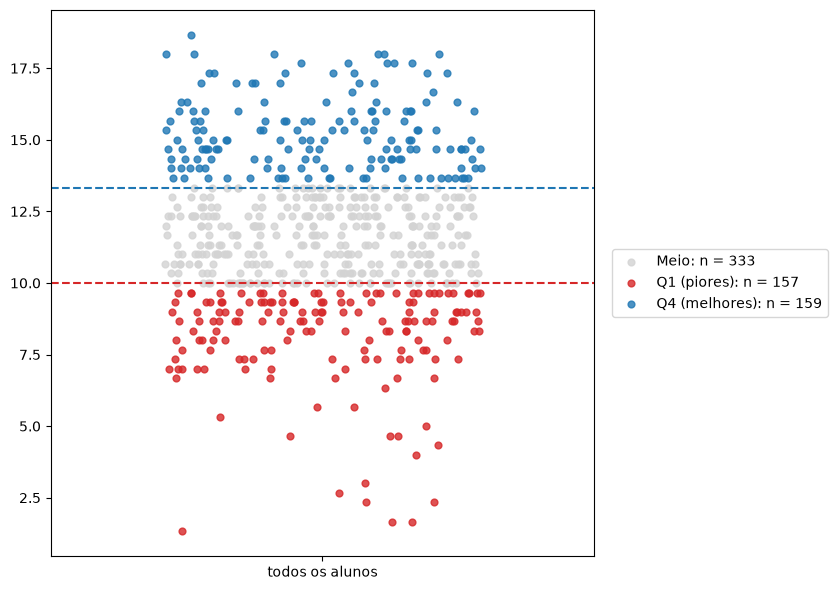

In [54]:
grafico_dispersao_quartis(df_port, "media_notas")

## Analisar como as variáveis nominais se relacionam com as notas
- escola, sexo, regiao, desejo_de_ensino_superior, tamanho_familia, convivencia_pais, trabalho_mae, trabalho_pai, motivo_escola, guardiao_legal.

# Mapa de calor que plota a relação das variáveis com as notas

In [55]:
def ajustar_bh(p):
    # correção para vários testes (Benjamini-Hochberg)
    p = np.asarray(p, dtype=float)
    n = len(p)
    ordem = np.argsort(p)
    ajustado = np.empty(n)
    minimo = 1.0
    for i in range(n - 1, -1, -1):
        idx = ordem[i]
        minimo = min(minimo, p[idx] * n / (i + 1))
        ajustado[idx] = minimo
    return ajustado


def relacao_com_notas(df, col_notas, nominais, disciplina=""):
    faltando = [c for c in col_notas + nominais if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) para cada variável e cada nota: teste de Kruskal-Wallis + tamanho do efeito
    linhas = []
    for nota in col_notas:
        for col in nominais:
            grupos = [g[nota].values for _, g in df.groupby(col)]
            if len(grupos) < 2:
                continue
            h, p = stats.kruskal(*grupos)
            n = sum(len(g) for g in grupos)
            eps2 = h / ((n ** 2 - 1) / (n + 1))          # tamanho do efeito (epsilon²)
            medias = df.groupby(col)[nota].mean()
            linhas.append({
                "nota": nota, "variavel": col,
                "tamanho_efeito": round(max(eps2, 0), 3), "p": p,
                "categoria_maior_media": medias.idxmax(), "media_maior": round(medias.max(), 1),
                "categoria_menor_media": medias.idxmin(), "media_menor": round(medias.min(), 1),
                "n_menor_grupo": int(df[col].value_counts().min()),
            })
    res = pd.DataFrame(linhas)
    res["p_ajustado"] = ajustar_bh(res["p"]).round(4)
    res["real?"] = np.where(res["p_ajustado"] < 0.05, "sim", "não")

    # 2) texto: tabela resumo (variável x nota)
    efeito = res.pivot(index="variavel", columns="nota", values="tamanho_efeito")[col_notas]
    efeito = efeito.loc[efeito.mean(axis=1).sort_values(ascending=False).index]
    real = res.pivot(index="variavel", columns="nota", values="real?")[col_notas].loc[efeito.index]
    anot = efeito.round(3).astype(str) + real.map(lambda x: "*" if x == "sim" else "")

    print("=" * 70)
    print(f"{disciplina}: relação de cada variável com as notas")
    print("(tamanho do efeito; * = diferença que não parece acaso)")
    print("=" * 70)
    print(anot.to_string())

    print("\nDetalhe: categoria com a maior e a menor média de nota")
    detalhe = res[["nota", "variavel", "tamanho_efeito", "p_ajustado", "real?",
                   "categoria_maior_media", "media_maior", "categoria_menor_media",
                   "media_menor", "n_menor_grupo"]]
    print(detalhe.sort_values(["nota", "tamanho_efeito"], ascending=[True, False]).to_string(index=False))

    # 3) gráfico: mapa de calor do tamanho do efeito
    plt.figure(figsize=(7, 0.55 * len(efeito) + 2))
    sns.heatmap(efeito, annot=anot, fmt="", cmap="Reds", vmin=0, vmax=0.15,
                linewidths=0.5, cbar_kws={"label": "tamanho do efeito (0 = nenhum)"})
    plt.title(f"{disciplina}: quanto cada variável se relaciona com as notas\n(* = não parece acaso)")
    plt.ylabel("")
    plt.xlabel("")
    plt.tight_layout()
    plt.show()
    return res

nominais = ["escola", "sexo", "regiao", "desejo_de_ensino_superior", "tamanho_familia",
            "convivencia_pais", "trabalho_mae", "trabalho_pai", "motivo_escola", "guardiao_legal"]
notas = ["nota_1p", "nota_2p", "nota_final"]

Português: relação de cada variável com as notas
(tamanho do efeito; * = diferença que não parece acaso)
nota                      nota_1p nota_2p nota_final
variavel                                            
desejo_de_ensino_superior  0.129*   0.12*     0.125*
escola                     0.091*  0.072*     0.081*
trabalho_mae               0.055*  0.051*     0.057*
motivo_escola              0.045*  0.049*     0.049*
trabalho_pai               0.034*   0.03*     0.027*
regiao                     0.027*  0.026*     0.029*
guardiao_legal             0.022*  0.014*     0.012*
sexo                       0.014*  0.015*     0.018*
tamanho_familia             0.002   0.001        0.0
convivencia_pais              0.0     0.0        0.0

Detalhe: categoria com a maior e a menor média de nota
      nota                  variavel  tamanho_efeito  p_ajustado real? categoria_maior_media  media_maior categoria_menor_media  media_menor  n_menor_grupo
   nota_1p desejo_de_ensino_superior           

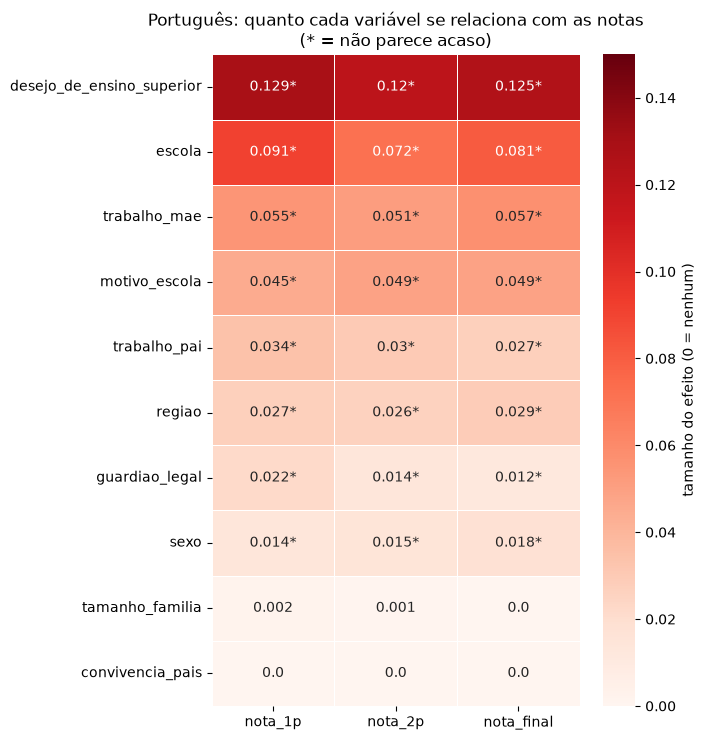

In [56]:
res_port = relacao_com_notas(df_port, notas, nominais, disciplina="Português")

Diante do mapa de calor, retiro as variáveis convivência_pais, tamanho_familia e guardiao_legal pela sua pequena relação com as notas.

In [57]:
nominais_foco = ["escola", "regiao", "sexo", "desejo_de_ensino_superior", "trabalho_mae", "trabalho_pai", "motivo_escola", "consumo_alcool_semana", "consumo_alcool_fim_de_semana"]

# Como as variavéis se distribuem entre o primeiro e quarto quartil - Q1 e Q4

In [58]:
def ajustar_bh(p):
    # correção para vários testes (Benjamini-Hochberg)
    p = np.asarray(p, dtype=float)
    n = len(p)
    ordem = np.argsort(p)
    ajustado = np.empty(n)
    minimo = 1.0
    for i in range(n - 1, -1, -1):
        idx = ordem[i]
        minimo = min(minimo, p[idx] * n / (i + 1))
        ajustado[idx] = minimo
    return ajustado


def criar_grupos(df, col_nota):
    # Q1 = nota MENOR que o 1º quartil | Q4 = nota MAIOR que o 3º quartil
    q1, q3 = df[col_nota].quantile([0.25, 0.75])
    grupo = np.select([df[col_nota] < q1, df[col_nota] > q3], ["Q1", "Q4"], default="meio")
    return grupo, q1, q3


def comparar_variavel(df, col_nota, col):
    grupo, q1, q3 = criar_grupos(df, col_nota)
    d = df.assign(grupo=grupo)
    d = d[d["grupo"] != "meio"]                      # ignora o meio
    tab = pd.crosstab(d[col], d["grupo"])            # contagens por categoria
    for g in ["Q1", "Q4"]:
        if g not in tab:
            tab[g] = 0
    if tab.shape[0] < 2:                             # só 1 categoria: nada a comparar
        return None
    pct = tab / tab.sum() * 100                      # % da categoria DENTRO de cada grupo
    dif = pct["Q1"] - pct["Q4"]
    chi2, p_chi2, _, _ = stats.chi2_contingency(tab, correction=False)
    p = stats.fisher_exact(tab)[1] if tab.shape == (2, 2) else p_chi2
    v = np.sqrt(chi2 / tab.values.sum() / (min(tab.shape) - 1))   # V de Cramér
    detalhe = pd.DataFrame({"n_Q1": tab["Q1"], "n_Q4": tab["Q4"],
                            "%_Q1": pct["Q1"].round(1), "%_Q4": pct["Q4"].round(1),
                            "dif_pp": dif.round(1)})
    return detalhe, v, p


def analisar_extremos(df, col_nota, nominais, disciplina="", mostrar_detalhes=False, ncols=3):
    faltando = [c for c in [col_nota] + nominais if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) calcula tudo (uma comparação por variável)
    detalhes, linhas = {}, []
    for col in nominais:
        r = comparar_variavel(df, col_nota, col)
        if r is None:
            continue
        detalhe, v, p = r
        detalhes[col] = detalhe
        cat = detalhe["dif_pp"].abs().idxmax()       # categoria com a maior diferença
        linhas.append({"variavel": col, "V": round(v, 3), "p": p, "categoria": cat,
                       "%_Q1": detalhe.loc[cat, "%_Q1"], "%_Q4": detalhe.loc[cat, "%_Q4"],
                       "dif_pp": detalhe.loc[cat, "dif_pp"]})
    rank = pd.DataFrame(linhas)
    rank["p_ajustado"] = ajustar_bh(rank["p"]).round(4)
    rank["real?"] = np.where(rank["p_ajustado"] < 0.05, "sim", "não")
    rank = rank.drop(columns="p").sort_values("V", ascending=False)

    # 2) texto: quartis, tamanho dos grupos e ranking das variáveis
    grupo, q1, q3 = criar_grupos(df, col_nota)
    print("=" * 75)
    print(f"{disciplina} | {col_nota}")
    print("=" * 75)
    print(f"Q1 (25%) = {q1:.2f} | Q3 (75%) = {q3:.2f} | alunos com média zero: {(df[col_nota] == 0).sum()}")
    print(f"Grupo Q1 (nota < {q1:.2f}): {(grupo == 'Q1').sum()} alunos | "
          f"Grupo Q4 (nota > {q3:.2f}): {(grupo == 'Q4').sum()} alunos | "
          f"meio (ignorado): {(grupo == 'meio').sum()}")
    print("\nVariáveis ordenadas pelo quanto separam o Q1 do Q4:")
    print(rank.to_string(index=False))
    if mostrar_detalhes:
        for col, det in detalhes.items():
            print(f"\n--- {col} ---")
            print(det.to_string())

    # 3) gráfico: uma figura só, um painel por variável
    colunas = list(detalhes.keys())
    nrows = int(np.ceil(len(colunas) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.8 * nrows),
                             sharey=True, squeeze=False)
    axes = axes.ravel()
    for k, (ax, col) in enumerate(zip(axes, colunas)):
        det = detalhes[col]
        linha = rank[rank["variavel"] == col].iloc[0]
        x = np.arange(len(det))
        barras_q1 = ax.bar(x - 0.2, det["%_Q1"], width=0.4, color="tab:red", label="Q1 (piores)")
        barras_q4 = ax.bar(x + 0.2, det["%_Q4"], width=0.4, color="tab:blue", label="Q4 (melhores)")
        ax.bar_label(barras_q1, fmt="%.0f%%", fontsize=8)
        ax.bar_label(barras_q4, fmt="%.0f%%", fontsize=8)
        ax.set_xticks(x)
        ax.set_xticklabels(det.index.astype(str), fontsize=8)
        ax.set_ylim(0, 110)
        ax.set_title(f"{col}\n(V={linha['V']:.2f}, real? {linha['real?']})")
        if k % ncols == 0:
            ax.set_ylabel("% dos alunos do grupo")
    for ax in axes[len(colunas):]:                   # esconde os quadros que sobraram
        ax.set_visible(False)
    axes[0].legend(loc="upper left", fontsize=8)
    fig.suptitle(f"{disciplina}: perfil dos piores (Q1) e melhores (Q4) alunos pela {col_nota}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

Português | media_notas
Q1 (25%) = 10.00 | Q3 (75%) = 13.33 | alunos com média zero: 0
Grupo Q1 (nota < 10.00): 157 alunos | Grupo Q4 (nota > 13.33): 159 alunos | meio (ignorado): 333

Variáveis ordenadas pelo quanto separam o Q1 do Q4:
                    variavel     V  categoria  %_Q1  %_Q4  dif_pp  p_ajustado real?
   desejo_de_ensino_superior 0.415         no  29.3   0.0    29.3      0.0000   sim
                      escola 0.351         GP  39.5  74.2   -34.7      0.0000   sim
                trabalho_mae 0.323    at_home  30.6  11.9    18.6      0.0000   sim
               motivo_escola 0.282 reputation  12.7  31.4   -18.7      0.0000   sim
       consumo_alcool_semana 0.273          1  59.2  81.8   -22.5      0.0002   sim
consumo_alcool_fim_de_semana 0.242          1  31.8  45.9   -14.1      0.0015   sim
                trabalho_pai 0.187    teacher   2.5  10.7    -8.1      0.0261   sim
                      regiao 0.173          R  40.8  24.5    16.2      0.0034   sim
       

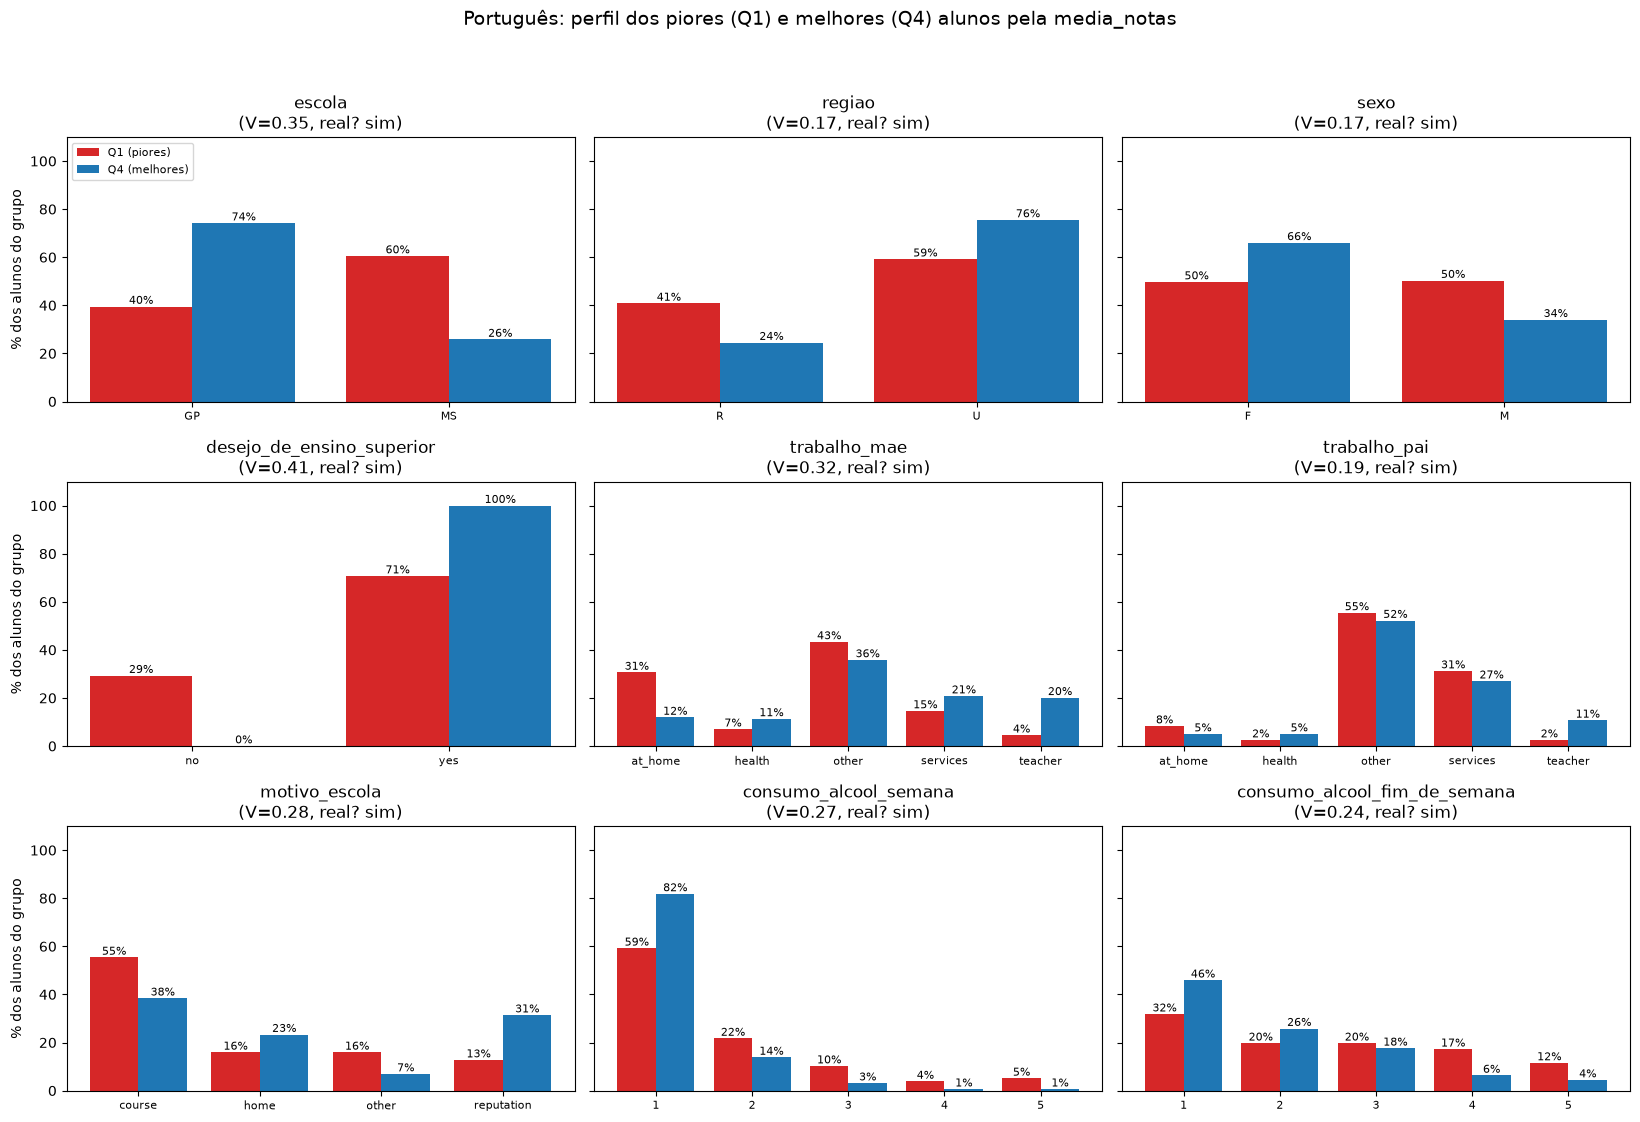

In [59]:
analisar_extremos(df_port, "media_notas", nominais_foco, disciplina="Português")

In [79]:
def analisar_extremos(df, col_nota, nominais, disciplina="", mostrar_detalhes=False, ncols=3):
    faltando = [c for c in [col_nota] + nominais if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) calcula tudo (uma comparação por variável)
    detalhes, linhas = {}, []
    for col in nominais:
        r = comparar_variavel(df, col_nota, col)
        if r is None:
            continue
        detalhe, v, p = r
        detalhes[col] = detalhe
        cat = detalhe["dif_pp"].abs().idxmax()       # categoria com a maior diferença
        linhas.append({"variavel": col, "V": round(v, 3), "p": p, "categoria": cat,
                       "%_Q1": detalhe.loc[cat, "%_Q1"], "%_Q4": detalhe.loc[cat, "%_Q4"],
                       "dif_pp": detalhe.loc[cat, "dif_pp"]})
    rank = pd.DataFrame(linhas)
    rank["p_ajustado"] = ajustar_bh(rank["p"]).round(4)
    rank["real?"] = np.where(rank["p_ajustado"] < 0.05, "sim", "não")
    rank = rank.drop(columns="p").sort_values("V", ascending=False)

    # 2) texto: quartis, tamanho dos grupos e ranking das variáveis
    grupo, q1, q3 = criar_grupos(df, col_nota)
    print("=" * 75)
    print(f"{disciplina} | {col_nota}")
    print("=" * 75)
    print(f"Q1 (25%) = {q1:.2f} | Q3 (75%) = {q3:.2f} | alunos com média zero: {(df[col_nota] == 0).sum()}")
    print(f"Grupo Q1 (nota < {q1:.2f}): {(grupo == 'Q1').sum()} alunos | "
          f"Grupo Q4 (nota > {q3:.2f}): {(grupo == 'Q4').sum()} alunos | "
          f"meio (ignorado): {(grupo == 'meio').sum()}")
    print("\nVariáveis ordenadas pelo quanto separam o Q1 do Q4:")
    print(rank.to_string(index=False))
    if mostrar_detalhes:
        for col, det in detalhes.items():
            print(f"\n--- {col} ---")
            print(det.to_string())

    # 3) gráfico: uma figura só, um painel por variável
    colunas = list(detalhes.keys())
    nrows = int(np.ceil(len(colunas) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.8 * nrows),
                             sharey=True, squeeze=False)
    axes = axes.ravel()
    for k, (ax, col) in enumerate(zip(axes, colunas)):
        det = detalhes[col]
        linha = rank[rank["variavel"] == col].iloc[0]
        x = np.arange(len(det))
        barras_q1 = ax.bar(x - 0.2, det["%_Q1"], width=0.4, color="tab:red", label="Q1 (piores)")
        barras_q4 = ax.bar(x + 0.2, det["%_Q4"], width=0.4, color="tab:blue", label="Q4 (melhores)")
        ax.bar_label(barras_q1, fmt="%.0f%%", fontsize=8)
        ax.bar_label(barras_q4, fmt="%.0f%%", fontsize=8)
        ax.set_xticks(x)
        ax.set_xticklabels(det.index.astype(str), fontsize=8)
        ax.set_ylim(0, 60)
        ax.set_title(f"{col}\n(V={linha['V']:.2f}, real? {linha['real?']})")
        if k % ncols == 0:
            ax.set_ylabel("% dos alunos do grupo")
    for ax in axes[len(colunas):]:                   # esconde os quadros que sobraram
        ax.set_visible(False)
    axes[0].legend(loc="upper left", fontsize=8)
    fig.suptitle(f"{disciplina}: perfil dos piores (Q1) e melhores (Q4) alunos pela {col_nota}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [77]:
nominais_2 = ["trabalho_mae", "trabalho_pai"]

Português | media_notas
Q1 (25%) = 10.00 | Q3 (75%) = 13.33 | alunos com média zero: 0
Grupo Q1 (nota < 10.00): 157 alunos | Grupo Q4 (nota > 13.33): 159 alunos | meio (ignorado): 333

Variáveis ordenadas pelo quanto separam o Q1 do Q4:
    variavel     V categoria  %_Q1  %_Q4  dif_pp  p_ajustado real?
trabalho_mae 0.323   at_home  30.6  11.9    18.6      0.0000   sim
trabalho_pai 0.187   teacher   2.5  10.7    -8.1      0.0261   sim


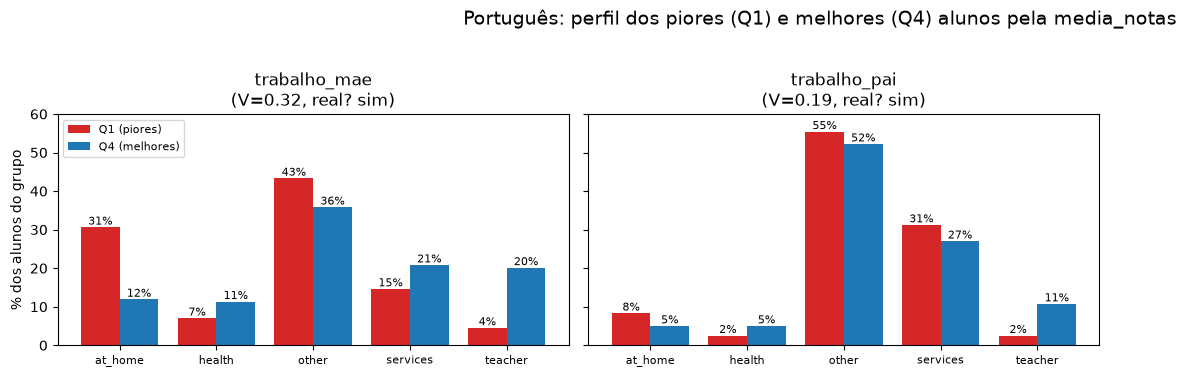

In [80]:
analisar_extremos(df_port, "media_notas", nominais_2, disciplina="Português")

OLHAR A DISTRUIBUIÇÃO DAS CATEGORIAS POR QUARTIL.

# Observação de como se comportam  as notas de quem deseja o ensino superior nas escolas.

In [60]:
def boxplots_por_lente(df, col_nota, col_foco, col_lente, titulo=""):
    faltando = [c for c in [col_nota, col_foco, col_lente] if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    cats_foco = sorted(df[col_foco].dropna().unique())     # ex.: no, yes
    cats_lente = sorted(df[col_lente].dropna().unique())   # ex.: GP, MS

    # 1) texto: tamanho dos grupos, média e mediana
    resumo = (df.groupby([col_lente, col_foco])[col_nota]
                .agg(n="size", media="mean", mediana="median").round(2))
    print("=" * 70)
    print(f"{titulo}: {col_nota} por {col_lente} e {col_foco}")
    print("=" * 70)
    print(resumo.to_string())

    # 2) texto: diferença de média entre as duas categorias do foco, dentro de cada lente
    if len(cats_foco) == 2:
        a, b = cats_foco
        linhas = []
        for lente in cats_lente:
            sub = df[df[col_lente] == lente]
            ga = sub[sub[col_foco] == a][col_nota]
            gb = sub[sub[col_foco] == b][col_nota]
            if len(ga) < 1 or len(gb) < 1:
                continue
            p = stats.mannwhitneyu(gb, ga).pvalue          # a diferença parece acaso?
            linhas.append({col_lente: lente, f"n_{a}": len(ga), f"n_{b}": len(gb),
                           f"dif_media ({b} - {a})": round(gb.mean() - ga.mean(), 2),
                           "p": round(p, 4), "real?": "sim" if p < 0.05 else "não"})
        print(f"\nDiferença de média ({b} - {a}) dentro de cada {col_lente}:")
        print(pd.DataFrame(linhas).to_string(index=False))

    # 3) gráfico: um painel por categoria da lente, lado a lado
    fig, axes = plt.subplots(1, len(cats_lente), figsize=(5.5 * len(cats_lente), 4.2),
                             sharey=True, squeeze=False)
    for ax, lente in zip(axes[0], cats_lente):
        sub = df[df[col_lente] == lente]
        contagem = sub[col_foco].value_counts()
        rotulos = [f"{c}\n(n={contagem.get(c, 0)})" for c in cats_foco]
        sns.boxplot(data=sub, x=col_foco, y=col_nota, order=cats_foco, ax=ax)
        ax.set_xticks(range(len(cats_foco)))
        ax.set_xticklabels(rotulos)
        ax.set_xlabel("")
        ax.set_title(f"{col_lente} = {lente}")
    fig.suptitle(f"{titulo}: {col_nota} por {col_foco}, separada por {col_lente}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

Português: media_notas por escola e desejo_de_ensino_superior
                                    n  media  mediana
escola desejo_de_ensino_superior                     
GP     no                          32   9.11     9.17
       yes                        391  12.49    12.33
MS     no                          37   8.40     9.00
       yes                        189  10.89    10.67

Diferença de média (yes - no) dentro de cada escola:
escola  n_no  n_yes  dif_media (yes - no)   p real?
    GP    32    391                  3.38 0.0   sim
    MS    37    189                  2.49 0.0   sim


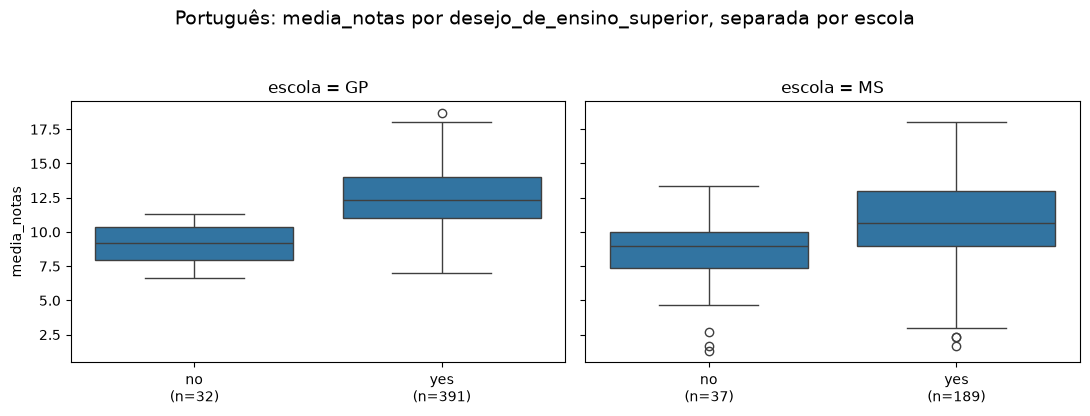

In [61]:
boxplots_por_lente(df_port, "media_notas", "desejo_de_ensino_superior", "escola", titulo="Português")

# Perguntas
- A desvantagem de MS é composição? olhar região, sexo, trabalho da mãe/pai e motivo da escolha da escola.
- O trabalho do pai é mais importante para as notas do que o trabalho do pai?
- A escola MS está em qual ambiente? Rural ou urbano?

# Composição de MS:
- Diante do exposto no quarto quartil, percebemos que a escola MS possui menos alunos no quarto quartil, ou seja, com maiores notas. Isso se deve a composição dos alunos?

A escola MS possui 14 alunos com nota zero na terceira prova e alguns zeros na segunda prova. Vou considerar que eles abandonaram o curso e retirá-los do dataframe.

In [62]:
df_port1 = df_port[~(df_port["nota_final"] == 0)]


Português: media_notas por escola e regiao
                 n  media  mediana
escola regiao                     
GP     R        78  11.79    11.33
       U       344  12.35    12.33
MS     R       109  10.94    10.33
       U       103  10.95    10.00

Diferença de média (U - R) dentro de cada escola:
escola  n_R  n_U  dif_media (U - R)      p real?
    GP   78  344               0.56 0.0394   sim
    MS  109  103               0.01 0.7021   não


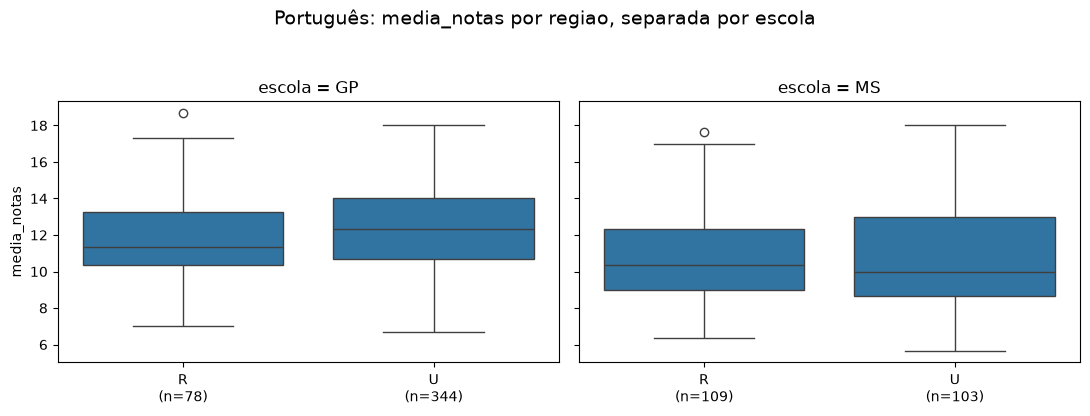

In [63]:
boxplots_por_lente(df_port1, "media_notas", "regiao", "escola", titulo="Português")

A escola MS possui mais alunos da região rural e consequentemente, notas menores.

Português: media_notas por escola e sexo
               n  media  mediana
escola sexo                     
GP     F     237  12.60    12.33
       M     185  11.80    11.67
MS     F     139  11.16    10.67
       M      73  10.56    10.00

Diferença de média (M - F) dentro de cada escola:
escola  n_F  n_M  dif_media (M - F)      p real?
    GP  237  185               -0.8 0.0003   sim
    MS  139   73               -0.6 0.2579   não


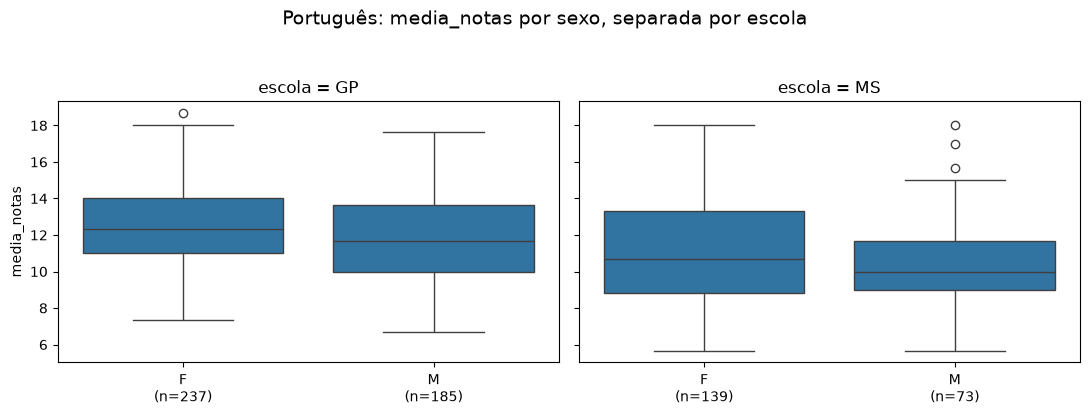

In [64]:
boxplots_por_lente(df_port1, "media_notas", "sexo", "escola", titulo="Português")

- A questão do sexo não parece ser algo muito influenciável aqui, pois possui mais mulheres que homens, apesar das mulheres da escola GP terem notas maiores que as mulheres da MS. 
- A mesma coisa acontece com os homens. Homens da escola GP tem notas maiores que os homens da escola MS.

## Observar o trabalho da mãe/pai e região com as notas.

Português: media_notas por regiao e trabalho_mae
                       n  media  mediana
regiao trabalho_mae                     
R      at_home        59  11.19    10.67
       health          8  11.38    10.17
       other          78  11.20    11.00
       services       28  11.02    10.67
       teacher        14  12.83    12.83
U      at_home        72  10.83    10.33
       health         40  12.97    13.00
       other         172  11.90    12.00
       services      107  12.13    12.33
       teacher        56  13.12    13.00


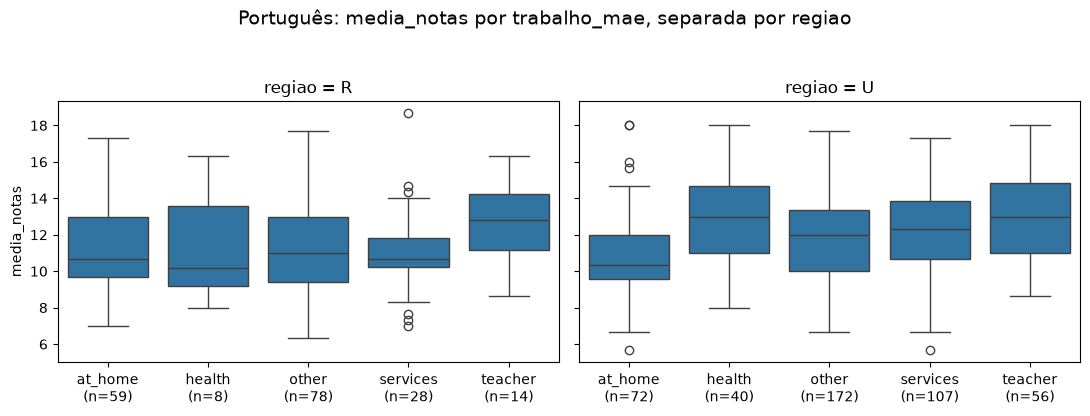

In [65]:
boxplots_por_lente(df_port1, "media_notas", "trabalho_mae", "regiao", titulo="Português")

- Na região urbana, se percebe que os estudantes com a mãe que trabalham na área da saúde e como professores, possuem notas maiores que o restante.
- Enquanto isso, na região rural, apesar das pequenas quantidade, se percebe que alunos cujas mães são professores, possuem notas maiores.

Português: media_notas por regiao e trabalho_pai
                       n  media  mediana
regiao trabalho_pai                     
R      at_home        10  11.43    10.50
       health          3  10.67    10.33
       other         115  11.22    11.00
       services       51  11.03    10.33
       teacher         8  14.21    14.83
U      at_home        31  10.96    10.67
       health         20  12.53    13.00
       other         244  12.04    12.00
       services      125  11.90    11.67
       teacher        27  13.41    13.33


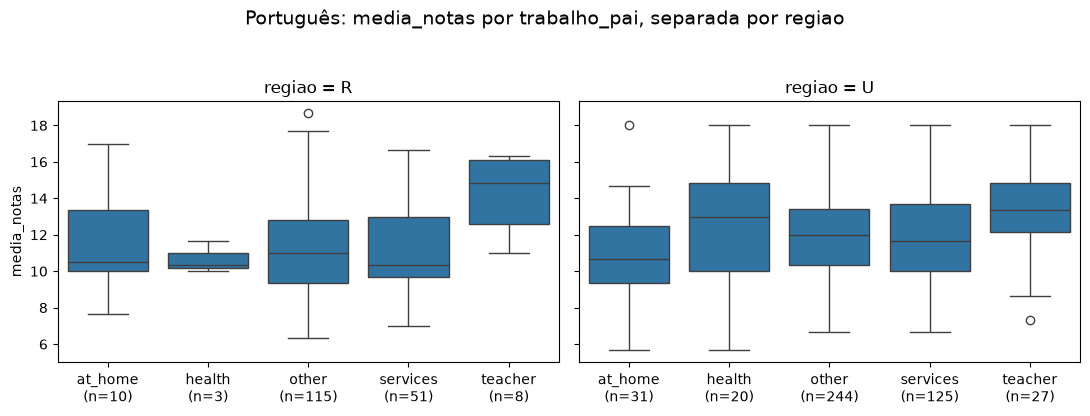

In [66]:
boxplots_por_lente(df_port1, "media_notas", "trabalho_pai", "regiao", titulo="Português")

- Na região urbana, se observa aqui que o mesmo padrão, que filhos cujos pais trabalham com saúde e educação, possuem notas maiores.
- Na região rural, pela grande concentração do trabalho do pai estar em 'other', o boxplot possui uma aparência distorcida. Apesar disso, percebe-se a pequena variância das notas nos alunos cujos pais são professores e, ao mesmo tempo, notas maiores.

Diante disso, posso concluir que em ambas as regiões, filhos de professores e de profissionais da saúde tendem a ter médias maiores. No entanto, o pai só se destaca pontualmente em teacher – especialmente no rural, com n=8 –, enquanto a mãe apresenta associação mais ampla e consitente. No rural, o tamanho amostral impede conclusões firmes.

# Observar o motivo da escolha da escola:

Português: media_notas por escola e motivo_escola
                        n  media  mediana
escola motivo_escola                     
GP     course         166  11.83    11.67
       home           115  12.25    12.33
       other           27  12.11    12.00
       reputation     114  12.89    13.00
MS     course         114  10.70    10.00
       home            31  11.25    10.67
       other           40  10.64    10.17
       reputation      27  12.12    12.33


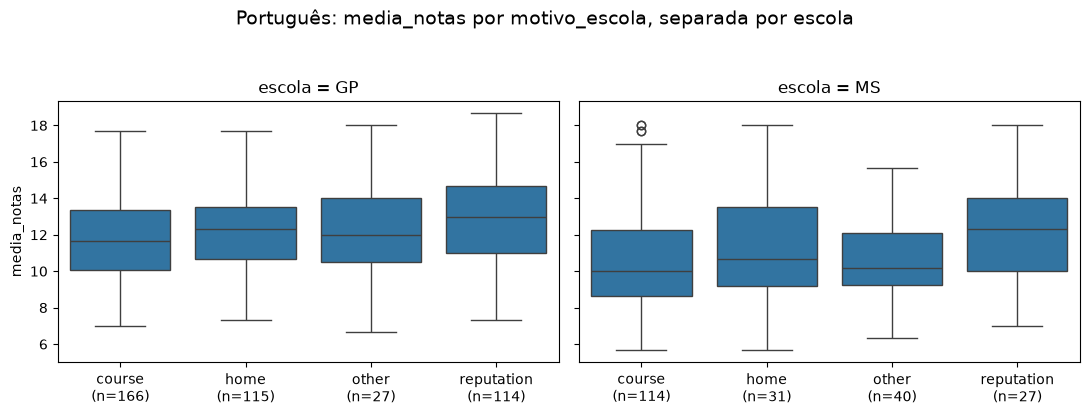

In [67]:
boxplots_por_lente(df_port1, "media_notas", "motivo_escola", "escola", titulo="Português")

## LENTE POR QUARTIL:


In [68]:

def quartis_por_lente(df, col_nota, col_foco, col_lente, titulo="", mostrar_n_categoria=True):
    faltando = [c for c in [col_nota, col_foco, col_lente] if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    cats_foco = sorted(df[col_foco].dropna().unique())     # categorias da variável analisada
    cats_lente = sorted(df[col_lente].dropna().unique())   # ex.: GP, MS

    fig, axes = plt.subplots(1, len(cats_lente), figsize=(5.5 * len(cats_lente), 4.6),
                             sharey=True, squeeze=False)

    for k, (ax, lente) in enumerate(zip(axes[0], cats_lente)):
        sub = df[df[col_lente] == lente]

        # 1) cortes calculados DENTRO desta escola (Q1: abaixo do 1º quartil | Q4: acima do 3º)
        q1, q3 = sub[col_nota].quantile([0.25, 0.75])
        grupo = np.select([sub[col_nota] < q1, sub[col_nota] > q3], ["Q1", "Q4"], default="meio")
        sub = sub.assign(grupo=grupo)
        extremos = sub[sub["grupo"] != "meio"]
        n_q1 = (sub["grupo"] == "Q1").sum()
        n_q4 = (sub["grupo"] == "Q4").sum()
        n_meio = (sub["grupo"] == "meio").sum()

        # 2) contagens e porcentagens de cada categoria DENTRO de cada grupo
        tab = (pd.crosstab(extremos[col_foco], extremos["grupo"])
                 .reindex(index=cats_foco, columns=["Q1", "Q4"], fill_value=0))
        pct = tab / tab.sum() * 100

        # 3) teste: a composição do Q1 é diferente da do Q4?
        tab_teste = tab.loc[tab.sum(axis=1) > 0]
        if tab_teste.shape[0] < 2:
            p = np.nan
        elif tab_teste.shape == (2, 2):
            p = stats.fisher_exact(tab_teste)[1]
        else:
            p = stats.chi2_contingency(tab_teste, correction=False)[1]

        # 4) texto: cortes, tamanho dos grupos e tabela
        print("=" * 70)
        print(f"{titulo} | {col_lente} = {lente} | {col_foco}")
        print("=" * 70)
        print(f"Q1: {col_nota} < {q1:.2f} ({n_q1} alunos) | Q4: {col_nota} > {q3:.2f} ({n_q4} alunos) | "
              f"meio ignorado: {n_meio} alunos | total: {len(sub)}")
        saida = pd.DataFrame({
            "n_Q1": tab["Q1"], "n_Q4": tab["Q4"],
            "%_Q1": pct["Q1"].round(1), "%_Q4": pct["Q4"].round(1),
            "%_na_escola": (sub[col_foco].value_counts(normalize=True) * 100)
                           .reindex(cats_foco).fillna(0).round(1),
            "n_na_escola": sub[col_foco].value_counts().reindex(cats_foco).fillna(0).astype(int),
        })
        saida["aviso"] = np.where(saida["n_na_escola"] < 20, "grupo pequeno", "")
        print(saida.to_string())
        if not np.isnan(p):
            print(f"Composição do Q1 diferente da do Q4? p = {p:.4f} -> "
                  f"{'sim' if p < 0.05 else 'não há evidência suficiente'}\n")

        # 5) gráfico: porcentagens do Q1 e do Q4 por categoria
        x = np.arange(len(cats_foco))
        barras_q1 = ax.bar(x - 0.2, pct["Q1"], width=0.4, color="tab:red", label="Q1 (piores)")
        barras_q4 = ax.bar(x + 0.2, pct["Q4"], width=0.4, color="tab:blue", label="Q4 (melhores)")
        ax.bar_label(barras_q1, fmt="%.0f%%", fontsize=9)
        ax.bar_label(barras_q4, fmt="%.0f%%", fontsize=9)
        ax.set_xticks(x)
        if mostrar_n_categoria:
            rotulos = [f"{c}\nQ1:{tab.loc[c, 'Q1']} | Q4:{tab.loc[c, 'Q4']}" for c in cats_foco]
        else:
            rotulos = [str(c) for c in cats_foco]
        ax.set_xticklabels(rotulos, fontsize=8)
        ax.set_ylim(0, 110)
        ax.set_title(f"{col_lente} = {lente}")
        if k == 0:
            ax.set_ylabel("% dos alunos do grupo")
            ax.legend(loc="upper left", fontsize=8)

    fig.suptitle(f"{titulo}: {col_foco} nos grupos Q1 e Q4 de {col_nota}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

# Presença nos quartis de desejo de ensino superior por escola 

Português | escola = GP | desejo_de_ensino_superior
Q1: media_notas < 10.67 (104 alunos) | Q4: media_notas > 13.67 (104 alunos) | meio ignorado: 215 alunos | total: 423
                           n_Q1  n_Q4  %_Q1   %_Q4  %_na_escola  n_na_escola aviso
desejo_de_ensino_superior                                                         
no                           27     0  26.0    0.0          7.6           32      
yes                          77   104  74.0  100.0         92.4          391      
Composição do Q1 diferente da do Q4? p = 0.0000 -> sim

Português | escola = MS | desejo_de_ensino_superior
Q1: media_notas < 8.67 (48 alunos) | Q4: media_notas > 12.67 (53 alunos) | meio ignorado: 125 alunos | total: 226
                           n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola aviso
desejo_de_ensino_superior                                                        
no                           14     2  29.2   3.8         16.4           37      
yes                          34

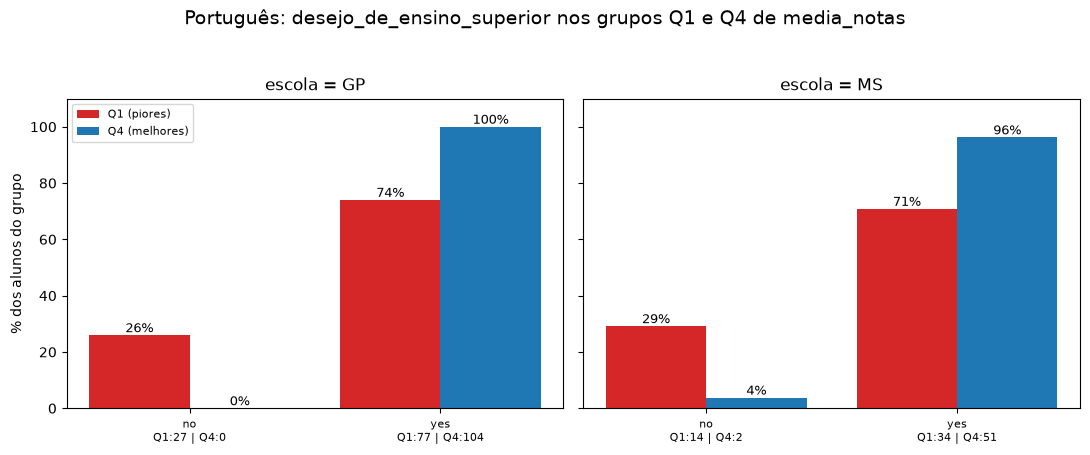

In [69]:
quartis_por_lente(df_port, "media_notas", "desejo_de_ensino_superior", "escola", titulo="Português")


# Presença nos quartis de sexo por escola 

Português | escola = GP | sexo
Q1: media_notas < 10.67 (104 alunos) | Q4: media_notas > 13.67 (104 alunos) | meio ignorado: 215 alunos | total: 423
      n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola aviso
sexo                                                        
F       39    64  37.5  61.5         56.0          237      
M       65    40  62.5  38.5         44.0          186      
Composição do Q1 diferente da do Q4? p = 0.0008 -> sim

Português | escola = MS | sexo
Q1: media_notas < 8.67 (48 alunos) | Q4: media_notas > 12.67 (53 alunos) | meio ignorado: 125 alunos | total: 226
      n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola aviso
sexo                                                        
F       32    41  66.7  77.4         64.6          146      
M       16    12  33.3  22.6         35.4           80      
Composição do Q1 diferente da do Q4? p = 0.2699 -> não há evidência suficiente



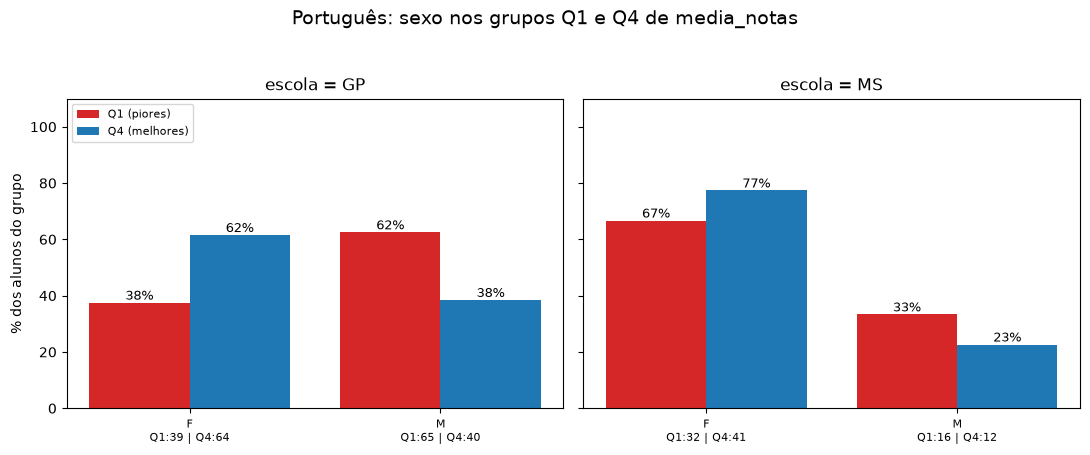

In [70]:
quartis_por_lente(df_port, "media_notas", "sexo", "escola", titulo="Português")


# Presença nos quartis do trabalho da mãe por escola 

Português | escola = GP | trabalho_mae
Q1: media_notas < 10.67 (104 alunos) | Q4: media_notas > 13.67 (104 alunos) | meio ignorado: 215 alunos | total: 423
              n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola aviso
trabalho_mae                                                        
at_home         23    10  22.1   9.6         14.9           63      
health           5    16   4.8  15.4          8.7           37      
other           43    32  41.3  30.8         38.3          162      
services        24    26  23.1  25.0         24.6          104      
teacher          9    20   8.7  19.2         13.5           57      
Composição do Q1 diferente da do Q4? p = 0.0022 -> sim

Português | escola = MS | trabalho_mae
Q1: media_notas < 8.67 (48 alunos) | Q4: media_notas > 12.67 (53 alunos) | meio ignorado: 125 alunos | total: 226
              n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola          aviso
trabalho_mae                                                              

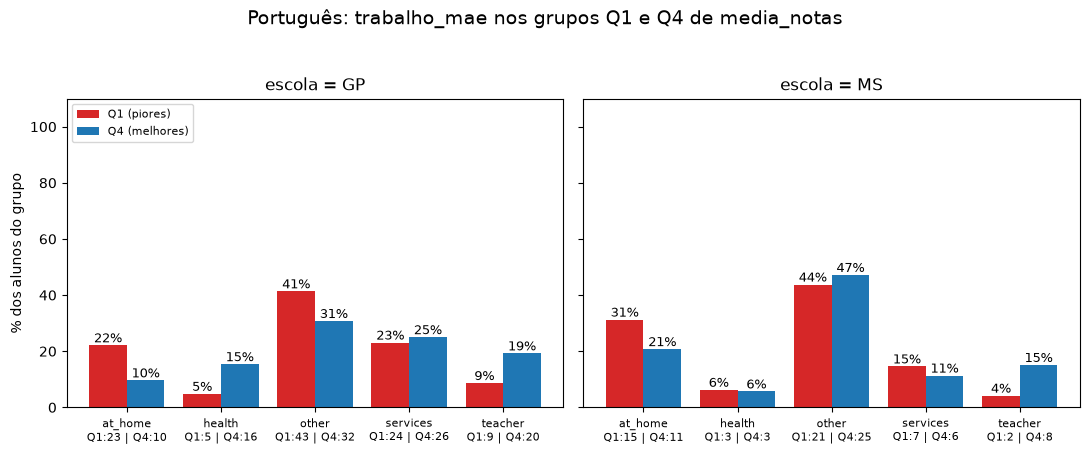

In [71]:
quartis_por_lente(df_port, "media_notas", "trabalho_mae", "escola", titulo="Português")

# Presença nos quartis do trabalho do pai por escola 

Português | escola = GP | trabalho_pai
Q1: media_notas < 10.67 (104 alunos) | Q4: media_notas > 13.67 (104 alunos) | meio ignorado: 215 alunos | total: 423
              n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola          aviso
trabalho_pai                                                                 
at_home          3     5   2.9   4.8          4.0           17  grupo pequeno
health           5     7   4.8   6.7          4.3           18  grupo pequeno
other           61    55  58.7  52.9         58.9          249               
services        31    26  29.8  25.0         25.8          109               
teacher          4    11   3.8  10.6          7.1           30               
Composição do Q1 diferente da do Q4? p = 0.3032 -> não há evidência suficiente

Português | escola = MS | trabalho_pai
Q1: media_notas < 8.67 (48 alunos) | Q4: media_notas > 12.67 (53 alunos) | meio ignorado: 125 alunos | total: 226
              n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola   

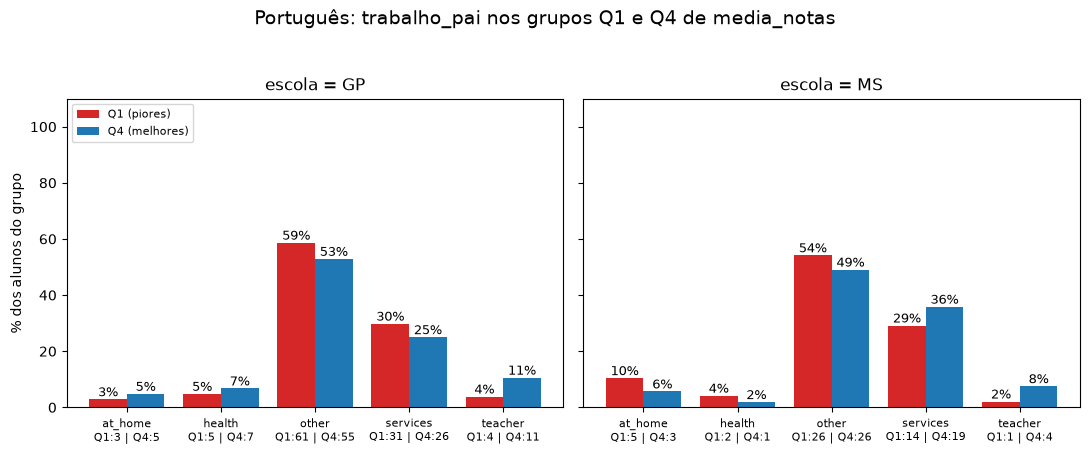

In [72]:
quartis_por_lente(df_port, "media_notas", "trabalho_pai", "escola", titulo="Português")

# Presença nos quartis do motivo da escola por escola 

Português | escola = GP | motivo_escola
Q1: media_notas < 10.67 (104 alunos) | Q4: media_notas > 13.67 (104 alunos) | meio ignorado: 215 alunos | total: 423
               n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola aviso
motivo_escola                                                        
course           51    35  49.0  33.7         39.5          167      
home             25    25  24.0  24.0         27.2          115      
other             7     7   6.7   6.7          6.4           27      
reputation       21    37  20.2  35.6         27.0          114      
Composição do Q1 diferente da do Q4? p = 0.0604 -> não há evidência suficiente

Português | escola = MS | motivo_escola
Q1: media_notas < 8.67 (48 alunos) | Q4: media_notas > 12.67 (53 alunos) | meio ignorado: 125 alunos | total: 226
               n_Q1  n_Q4  %_Q1  %_Q4  %_na_escola  n_na_escola aviso
motivo_escola                                                        
course           26    24  54.2  45.3         52.

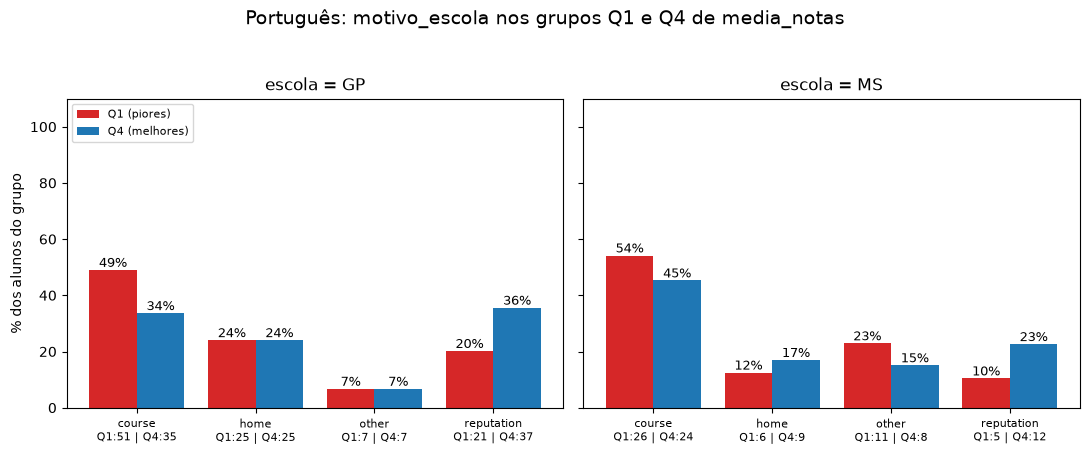

In [73]:
quartis_por_lente(df_port, "media_notas", "motivo_escola", "escola", titulo="Português")

# Consumo de álcool por região

In [ ]:
quartis_por_lente(df_port, "media_notas", "desejo_de_ensino_superior", "escola", titulo="Português")